# Member 3 XGBoost

Executable code for the frozen SBERT and XGBoost experiment. This notebook includes all Member 3 functions for integration into the final notebook. Run from the team repository. Use its `dsai4205` environment and `clean_v2` plus `folds_v1`. Existing `sbert_multi` caches are aligned to tweet IDs. Without a cache the code can generate embeddings with SentenceTransformer, or use the official float32 ONNX export via `--onnx-dir` in the script.

To regenerate the experiment, set `RUN_TRAINING = True`. The default shows the committed results and checks they match the supplied data without rewriting the team ledger. See `README_XGBoost.md` for the team prediction cache.

## Setup and versions

In [1]:
"""Member 3 XGBoost. Run from the repository root with the team environment."""
from __future__ import annotations

import argparse
from collections import Counter
import hashlib
import json
from pathlib import Path
import platform
import sys
from time import perf_counter

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from threadpoolctl import threadpool_limits
import xgboost as xgb

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src'/'config.py').is_file())
sys.path.insert(0, str(ROOT))
from src.cache import load_embedding, save_embedding, save_preds
from src.config import CLEAN_DIR, EMB_DIR, LABELS, N_FOLDS, SEED, SPLITS_DIR, VERSION_TAGS
from src.data import load_clean, load_splits
from src.evaluate import evaluate, new_run_id, plot_confusion, save_result

MODEL = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'
REVISION = '4328cf26390c98c5e3c738b4460a05b95f4911f5'
MAX_TOKENS = 82  # Member 5's development-only length rule for clean_v2/folds_v1.
LABEL_IDS = list(LABELS)
FEATURES = ['char_len', 'word_len', 'n_hashtags', 'n_mentions', 'n_cashtags',
            'n_exclaim', 'n_question', 'caps_ratio', 'hashtag_ratio', 'is_hashtag_spam',
            'domain_crypto', 'domain_india', 'domain_us']
DESCRIPTORS = FEATURES + ['emoji_lost']
GRID = (
    {'name': 'depth2', 'n_components': 64, 'max_depth': 2, 'learning_rate': .08, 'subsample': .85, 'reg_lambda': 4},
    {'name': 'depth3', 'n_components': 64, 'max_depth': 3, 'learning_rate': .05, 'subsample': .85, 'reg_lambda': 4},
    {'name': 'depth4', 'n_components': 96, 'max_depth': 4, 'learning_rate': .04, 'subsample': .75, 'reg_lambda': 8},
)
ENSEMBLE_NOTE = 'Nested outer OOF. No test labels used for comparison or model selection.'


def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

## Frozen SBERT embeddings

In [2]:
def sbert_vectors(clean, onnx_dir):
    """Generate the fixed team sentence vectors, or load an existing ID-indexed cache."""
    ids = clean.id.to_numpy()
    if onnx_dir is None and (EMB_DIR / 'sbert_multi.npy').is_file():
        cached_ids, cached = load_embedding('sbert_multi')
        if len(cached_ids) != len(ids) or set(cached_ids) != set(ids):
            raise ValueError('SBERT IDs must match the clean_v2 snapshot exactly.')
        vectors = load_embedding('sbert_multi', ids)
        source = 'existing team sbert_multi cache'
    elif onnx_dir:
        import onnxruntime as ort
        from tokenizers import Tokenizer

        tokenizer = Tokenizer.from_file(str(onnx_dir / 'tokenizer.json'))
        tokenizer.enable_truncation(max_length=MAX_TOKENS)
        tokenizer.enable_padding(pad_id=tokenizer.token_to_id('<pad>'), pad_token='<pad>')
        options = ort.SessionOptions()
        options.intra_op_num_threads = 4
        options.inter_op_num_threads = 1
        session = ort.InferenceSession(str(onnx_dir / 'model.onnx'), sess_options=options,
                                       providers=['CPUExecutionProvider'])
        input_names = {spec.name for spec in session.get_inputs()}
        vectors = []
        texts = clean.text_clean.tolist()
        for start in range(0, len(texts), 16):
            batch = tokenizer.encode_batch(texts[start:start + 16])
            attention = np.array([entry.attention_mask for entry in batch], dtype=np.int64)
            inputs = {'input_ids': np.array([entry.ids for entry in batch], dtype=np.int64),
                      'attention_mask': attention,
                      'token_type_ids': np.array([entry.type_ids for entry in batch], dtype=np.int64)}
            hidden, *_ = session.run(None, {k: inputs[k] for k in input_names})
            if hidden.ndim != 3 or hidden.shape[2] != 768:
                raise ValueError(f'Unexpected SBERT token output {hidden.shape}')
            pooled = (hidden * attention[..., None]).sum(1) / attention.sum(1, keepdims=True)
            vectors.append(pooled / np.linalg.norm(pooled, axis=1, keepdims=True))
            if start % 256 == 0:
                print(f'SBERT encoded {min(start + 16, len(texts))}/{len(texts)}', flush=True)
        vectors = np.vstack(vectors).astype(np.float32)
        source = 'recomputed from the official float32 ONNX export'
        save_embedding('sbert_multi', ids, vectors)
    else:
        from sentence_transformers import SentenceTransformer

        encoder = SentenceTransformer(MODEL, revision=REVISION, device='cpu', trust_remote_code=False)
        encoder.max_seq_length = MAX_TOKENS
        vectors = encoder.encode(clean.text_clean.tolist(), batch_size=16, normalize_embeddings=True,
                                 show_progress_bar=True)
        source = 'recomputed with SentenceTransformer'
        save_embedding('sbert_multi', ids, vectors)
    vectors = np.asarray(vectors, dtype=np.float32)
    if vectors.shape != (len(clean), 768) or not np.isfinite(vectors).all():
        raise ValueError(f'Expected finite SBERT vectors with shape ({len(clean)}, 768).')
    np.testing.assert_allclose(np.linalg.norm(vectors, axis=1), 1, rtol=.003, atol=.003)
    return vectors, source

## PCA, XGBoost and grouped tuning

In [3]:
def fit_predict(vectors, hand, y, train, predict, config, mode, *, stop=None, rounds=None):
    pca = PCA(n_components=config['n_components'], svd_solver='randomized', random_state=SEED)
    pca.fit(vectors[train])

    def features(indices):
        pcs = pca.transform(vectors[indices])
        return np.column_stack([pcs, hand[indices]]) if mode == 'combined' else pcs

    model = xgb.XGBClassifier(
        objective='multi:softprob', num_class=3, eval_metric='mlogloss', tree_method='hist',
        n_jobs=2, random_state=SEED, n_estimators=rounds or 160, min_child_weight=3,
        colsample_bytree=.85, max_depth=config['max_depth'], learning_rate=config['learning_rate'],
        subsample=config['subsample'], reg_lambda=config['reg_lambda'],
        early_stopping_rounds=12 if stop is not None else None,
    )
    options = {'eval_set': [(features(stop), y[stop])], 'verbose': False} if stop is not None else {}
    model.fit(features(train), y[train], **options)
    assert model.classes_.tolist() == LABEL_IDS
    iterations = model.best_iteration + 1 if stop is not None else rounds
    if predict is None:
        return None, iterations, model, None
    design = features(predict)
    return model.predict_proba(design), iterations, model, design


def choose(vectors, hand, y, groups, outer_train, mode, stage):
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    rows = []
    splits = list(inner.split(outer_train, y[outer_train], groups[outer_train]))
    for config in GRID:
        inner_pred = np.empty(len(outer_train), dtype=int)
        iterations = []
        for train, valid in splits:
            pred, rounds, _, _ = fit_predict(vectors, hand, y, outer_train[train], outer_train[valid],
                                             config, mode, stop=outer_train[valid])
            inner_pred[valid] = pred.argmax(axis=1)
            iterations.append(rounds)
        score = f1_score(y[outer_train], inner_pred, labels=LABEL_IDS, average='macro', zero_division=0)
        rows.append({'stage': stage, 'features': mode, **config, 'inner_macro_f1': float(score),
                     'early_stop_rounds': iterations, 'refit_rounds': int(np.median(iterations))})
    chosen_mode = max(rows, key=lambda row: row['inner_macro_f1'])['name']
    for row in rows:
        row['selected'] = row['name'] == chosen_mode
    return next(row for row in rows if row['selected']), rows

## Exact TreeSHAP

In [4]:
def shap_values(model, design, probabilities):
    booster = model.get_booster()
    matrix = xgb.DMatrix(design)
    values = booster.predict(matrix, pred_contribs=True, strict_shape=True)
    margins = booster.predict(matrix, output_margin=True)
    np.testing.assert_allclose(values.sum(axis=-1), margins, rtol=1e-4, atol=1e-5)
    scaled = np.exp(margins - margins.max(axis=1, keepdims=True))
    np.testing.assert_allclose(scaled / scaled.sum(axis=1, keepdims=True), probabilities, atol=1e-6)
    return values[:, :, :-1]


def shap_outputs(arr, output_path):
    # Fold-local PCs are not semantically aligned. Rank named descriptors across folds.
    table = pd.DataFrame(np.abs(arr).mean(axis=0).T, columns=[LABELS[i] for i in LABEL_IDS])
    table.insert(0, 'feature', DESCRIPTORS)
    table['mean_abs_shap'] = table.iloc[:, 1:].mean(axis=1)
    table = table.sort_values('mean_abs_shap', ascending=False)
    table.to_csv(output_path / 'm3_shap_descriptors.csv', index=False)
    top = table.head(8).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.8, 4.8), layout='constrained')
    positions = np.arange(len(top))
    for offset, label, color in zip([-.23, 0, .23], LABELS.values(), ['#64748b', '#008b76', '#cb573f']):
        ax.barh(positions + offset, top[label], height=.21, label=label, color=color)
    ax.set_yticks(positions, top.feature)
    ax.set_xlabel('Mean absolute TreeSHAP contribution to class margin')
    ax.set_title('Named features used by XGBoost on held-out folds', loc='left', fontweight='bold')
    ax.legend(frameon=False, ncol=3)
    ax.spines[['top', 'right']].set_visible(False)
    fig.savefig(output_path / 'm3_shap_global.png', dpi=210)
    plt.close(fig)
    return table

## Five official outer folds and final refit

In [5]:
def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--onnx-dir', type=Path, help='Official model.onnx and tokenizer.json at the pinned revision')
    parser.add_argument('--output', type=Path, help='Evidence directory (defaults to a new local run)')
    args = parser.parse_args(argv)
    out = (args.output or ROOT / 'local_artifacts' / 'xgboost' / new_run_id('xgboost', 'sbert_multi')).resolve()
    out.mkdir(parents=True, exist_ok=True)
    clean = load_clean().sort_values('id').reset_index(drop=True)
    splits = load_splits(clean=clean).set_index('id').loc[clean.id].reset_index()
    vectors, source = sbert_vectors(clean, args.onnx_dir)
    hand = clean[DESCRIPTORS].to_numpy(dtype=np.float32)
    if not np.isfinite(hand).all():
        raise ValueError('Missing or invalid values in the clean_v2 descriptors.')
    y = clean.label.to_numpy(dtype=int)
    groups = clean.group_id.to_numpy()
    dev = np.flatnonzero(splits.split.eq('train'))
    test = np.flatnonzero(splits.split.eq('test'))
    modes = ('combined', 'embedding_only')
    configs, per_fold, rows = [], [], []
    predictions = {mode: np.full((len(clean), 3), np.nan) for mode in modes}
    contributions = np.full((len(clean), 3, len(DESCRIPTORS)), np.nan)
    run_ids = {mode: new_run_id('xgboost', 'sbert_multi') for mode in modes}
    timings = Counter()
    local_components = []
    with threadpool_limits(2):
        for fold in range(N_FOLDS):
            outer_train = dev[splits.fold.iloc[dev].to_numpy() != fold]
            validation = dev[splits.fold.iloc[dev].to_numpy() == fold]
            assert set(groups[outer_train]).isdisjoint(groups[validation])
            for mode in modes:
                start = perf_counter()
                chosen, attempts = choose(vectors, hand, y, groups, outer_train, mode, f'outer_{fold}')
                configs.extend(attempts)
                probs, rounds, tree, design = fit_predict(vectors, hand, y, outer_train, validation,
                                                           chosen, mode, rounds=chosen['refit_rounds'])
                timings[mode] += perf_counter() - start
                predictions[mode][validation] = probs
                fold_score = f1_score(y[validation], probs.argmax(1), labels=LABEL_IDS, average='macro')
                per_fold.append({'fold': fold, 'features': mode, 'train_n': len(outer_train),
                                 'validation_n': len(validation), 'macro_f1': fold_score,
                                 'configuration': chosen['name'], 'rounds': rounds})
                if mode == 'combined':
                    vals = shap_values(tree, design, probs)
                    contributions[validation] = vals[:, :, -len(DESCRIPTORS):]
                    local_components.append(float(np.abs(vals[:, :, :-len(DESCRIPTORS)]).sum(axis=2).mean()))
                print(f'Outer fold {fold} {mode}: F1 {fold_score:.4f} ({chosen["name"]}, {rounds} rounds)', flush=True)

        assert np.isfinite(contributions[dev]).all()
        for mode in modes:
            assert np.isfinite(predictions[mode][dev]).all()
            np.testing.assert_allclose(predictions[mode][dev].sum(1), 1, atol=1e-6)
            chosen, attempts = choose(vectors, hand, y, groups, dev, mode, 'full_development')
            configs.extend(attempts)
            test_probs, rounds, _, _ = fit_predict(vectors, hand, y, dev, test, chosen, mode,
                                                   rounds=chosen['refit_rounds'])
            np.testing.assert_allclose(test_probs.sum(1), 1, atol=1e-6)
            run_id = run_ids[mode]
            save_preds(run_id, oof_ids=clean.id.to_numpy()[dev], oof_proba=predictions[mode][dev],
                       test_ids=clean.id.to_numpy()[test], test_proba=test_probs, classes=LABEL_IDS)
            row = evaluate(y[dev], predictions[mode][dev].argmax(1), run_id=run_id, model='xgboost',
                           embedding='sbert_multi', split='cv', params={'features': mode, 'final': chosen,
                           'encoder_revision': REVISION, 'max_tokens': MAX_TOKENS, 'inner_folds': 3},
                           train_seconds=timings[mode], notes=ENSEMBLE_NOTE)
            save_result(row, 'm3_xgboost')
            rows.append(row)

    pd.DataFrame(rows).to_csv(out / 'm3_xgboost.csv', index=False)
    pd.DataFrame(configs).to_csv(out / 'm3_inner_search.csv', index=False)
    pd.DataFrame(per_fold).to_csv(out / 'm3_fold_metrics.csv', index=False)
    conf = plot_confusion(y[dev], predictions['combined'][dev].argmax(1), 'XGBoost combined features · OOF',
                          save_as=out / 'm3_oof_confusion.png')
    plt.close(conf)
    shap = shap_outputs(contributions[dev], out)
    precision, recall, f1, support = precision_recall_fscore_support(
        y[dev], predictions['combined'][dev].argmax(1), labels=LABEL_IDS, zero_division=0)
    pd.DataFrame(dict(label=list(LABELS.values()), precision=precision, recall=recall, f1=f1, support=support)
                 ).to_csv(out / 'm3_per_class.csv', index=False)
    baseline = pd.read_csv(ROOT / 'results' / 'baseline.csv')
    baseline = baseline[(baseline.split == 'cv') & (baseline.data_version == VERSION_TAGS['data_version'])
                        & (baseline.split_version == VERSION_TAGS['split_version'])].iloc[0]
    summary = {**VERSION_TAGS, 'xgboost_version': xgb.__version__, 'sklearn_version': sklearn.__version__,
               'python_version': platform.python_version(), 'data_sha256': file_hash(CLEAN_DIR / 'clean_v2.csv'),
               'split_sha256': file_hash(SPLITS_DIR / 'folds_v1.csv'), 'model': MODEL, 'revision': REVISION,
               'embedding_source': source, 'max_tokens': MAX_TOKENS, 'development_n': len(dev),
               'test_prediction_n': len(test), 'test_metrics_computed': False,
               'recommended_run_id': run_ids['combined'], 'embedding_only_run_id': run_ids['embedding_only'],
               'baseline_run_id': baseline.run_id, 'baseline_macro_f1': float(baseline.macro_f1),
               'top_named_shap_features': shap.feature.head(5).tolist(),
               'mean_sum_absolute_pc_shap_per_fold': local_components, 'metrics': rows}
    (out / 'm3_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(pd.DataFrame(rows)[['run_id', 'accuracy', 'macro_f1']].to_string(index=False), flush=True)
    return summary

,run_id,accuracy,macro_f1,f1_neutral,f1_positive,f1_negative
0,xgboost__sbert_multi__20261121-143943-a632,0.582651,0.578881,0.60262,0.609615,0.524407
1,xgboost__sbert_multi__20261121-143943-eba1,0.542553,0.527475,0.45515,0.608372,0.518905


,label,precision,recall,f1,support
0,Neutral,0.610619,0.594828,0.602620,348
1,Positive,0.572202,0.652263,0.609615,486
2,Negative,0.571429,0.484536,0.524407,388


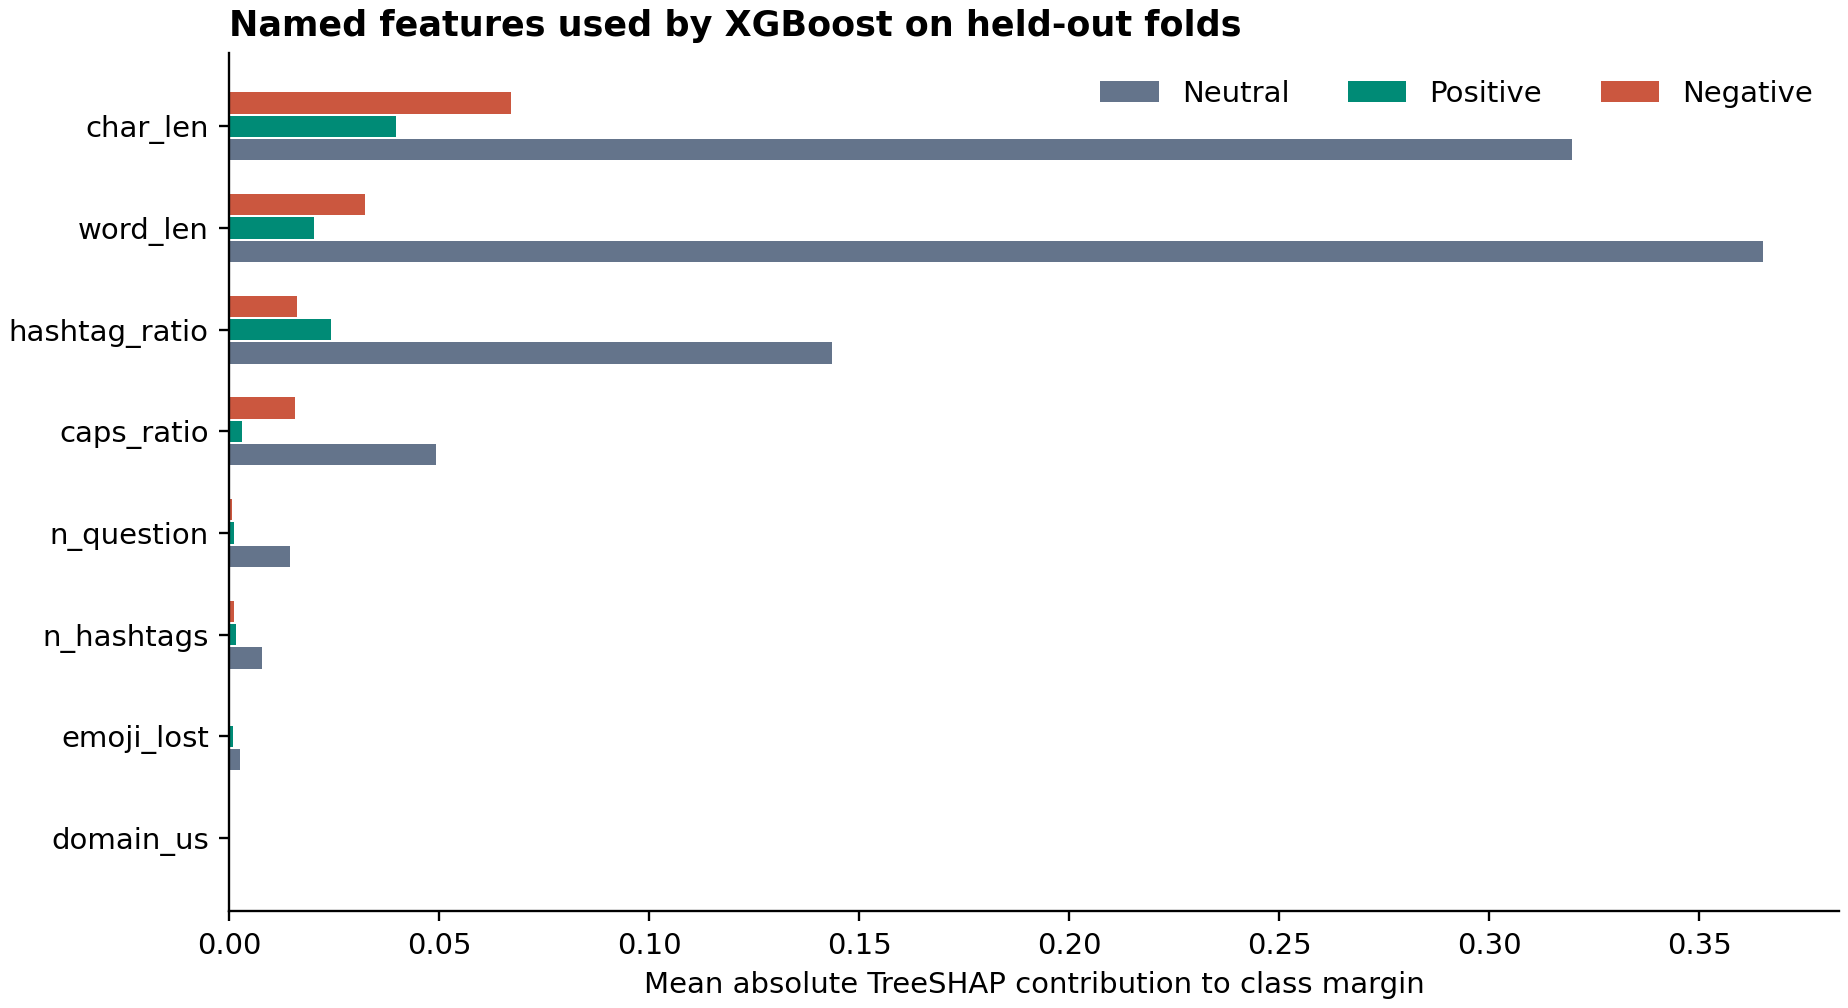

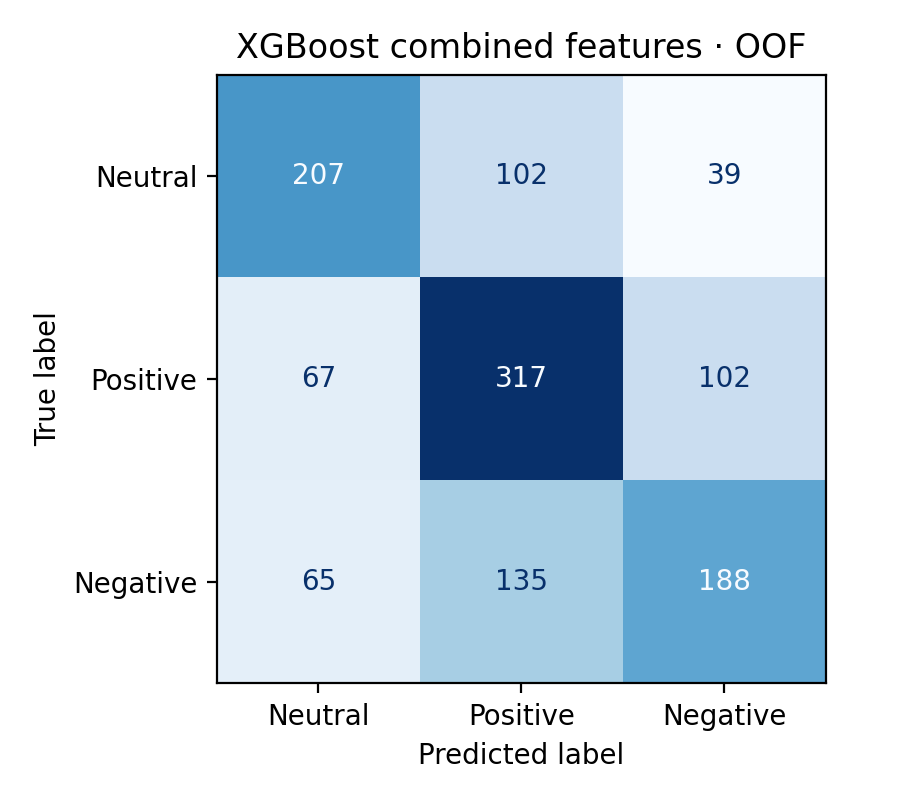

In [6]:
from IPython.display import Image, display

output = ROOT / 'experiments/Member3_file'
RUN_TRAINING = False
if RUN_TRAINING:
    output = ROOT / 'local_artifacts' / 'xgboost' / new_run_id('xgboost', 'sbert_multi')
    summary = main(['--output', str(output)])
else:
    summary = json.loads((output / 'm3_summary.json').read_text(encoding='utf-8'))
    assert summary['data_sha256'] == file_hash(CLEAN_DIR / 'clean_v2.csv')
    assert summary['split_sha256'] == file_hash(SPLITS_DIR / 'folds_v1.csv')
display(pd.read_csv(output / 'm3_xgboost.csv')[['run_id', 'accuracy', 'macro_f1', 'f1_neutral', 'f1_positive', 'f1_negative']])
display(pd.read_csv(output / 'm3_per_class.csv'))
display(Image(filename=str(output / 'm3_shap_global.png')))
display(Image(filename=str(output / 'm3_oof_confusion.png')))